# BBO capstone: method and results

This notebook walks through the optimisation run and regenerates every table and plot from the files in `data/`.

1. Load the submitted queries and the values the portal returned
2. Summarise progress per function
3. Plot each function's results by round
4. Inspect the model settings and diagnostics logged each round
5. Limits

Run all cells to reproduce the outputs. **Round 5 results were still pending when this was written**, so they are not in the analysis (the round 5 *queries* are logged in `data/rounds/`).

In [1]:
import csv, json, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=Warning)
DATA = Path("../data")
with open(DATA / "observations.csv", newline="") as fh:
    rows = list(csv.DictReader(fh))
print(f"{len(rows)} submitted queries with portal results")

32 submitted queries with portal results


## 1. Submitted queries and results
One row per query: function, round, query point, the value the portal returned (`y`), and the settings used.

In [2]:
by_fn = {}
for r in rows:
    by_fn.setdefault(int(r["function"]), []).append((int(r["round"]), float(r["y"]), r["query"]))
for f in sorted(by_fn):
    by_fn[f].sort()
    print(f"Function {f}:", [f"R{rnd}: {y:.4g}" for rnd, y, _ in by_fn[f]])

Function 1: ['R1: 1.225e-149', 'R2: -1.432e-44', 'R3: -2.165e-19', 'R4: -1.243e-07']
Function 2: ['R1: 0.4373', 'R2: 0.03479', 'R3: 0.6484', 'R4: 0.7022']
Function 3: ['R1: -0.1331', 'R2: -0.05227', 'R3: -0.04886', 'R4: -0.1596']
Function 4: ['R1: -3.617', 'R2: -1.136', 'R3: -15.7', 'R4: -22.08']
Function 5: ['R1: 150.2', 'R2: 1581', 'R3: 6065', 'R4: 8329']
Function 6: ['R1: -0.6031', 'R2: -0.5324', 'R3: -0.5075', 'R4: -0.5487']
Function 7: ['R1: 1.117', 'R2: 1.521', 'R3: 0.8328', 'R4: 1.755']
Function 8: ['R1: 9.808', 'R2: 9.78', 'R3: 9.922', 'R4: 9.956']


## 2. Progress per function
`best y` is the best portal result among my submitted queries. The capstone also supplied initial data (10 to 40 points per function) that the model was fitted on; it is not stored in this repo, so for functions 1 and 3 the overall best (taken from the round 5 log) is a pre-supplied point.

In [3]:
r5 = json.loads((DATA / "rounds" / "round_05_queries.json").read_text())
print(f"{'fn':>3} {'dim':>4} {'subm.':>6} {'best y (submitted)':>20} {'round':>6} {'best y overall*':>17} {'model pts':>10}")
for f in sorted(by_fn):
    dim = len(by_fn[f][0][2].split("-"))
    rnd, y, _ = max(by_fn[f], key=lambda t: t[1])
    d = r5["functions"][f"function_{f}"]["diagnostics"]
    print(f"{f:>3} {dim:>4} {len(by_fn[f]):>6} {y:>20.6g} {rnd:>6} {d['best_observed']:>17.6g} {d['n_points']:>10}")
print("* includes the supplied initial data and rounds up to 4 (model points before round 5's query)")

 fn  dim  subm.   best y (submitted)  round   best y overall*  model pts
  1    2      4         1.22538e-149      1       7.71088e-16         14
  2    2      4             0.702212      4          0.702212         14
  3    3      4           -0.0488583      3        -0.0348353         19
  4    4      4             -1.13603      2          -1.13603         34
  5    4      4              8328.68      4           8328.68         24
  6    5      4            -0.507517      3         -0.507517         24
  7    6      4              1.75494      4           1.75494         34
  8    8      4              9.95645      4           9.95645         44
* includes the supplied initial data and rounds up to 4 (model points before round 5's query)


## 3. Results by round
Dots are portal results for each submitted query; the line is the best so far among submitted queries. Each panel has its own axis. Function 5 uses a log axis because it spans two orders of magnitude, and Function 1's results are all effectively zero, so its panel shows a note instead of a plot.

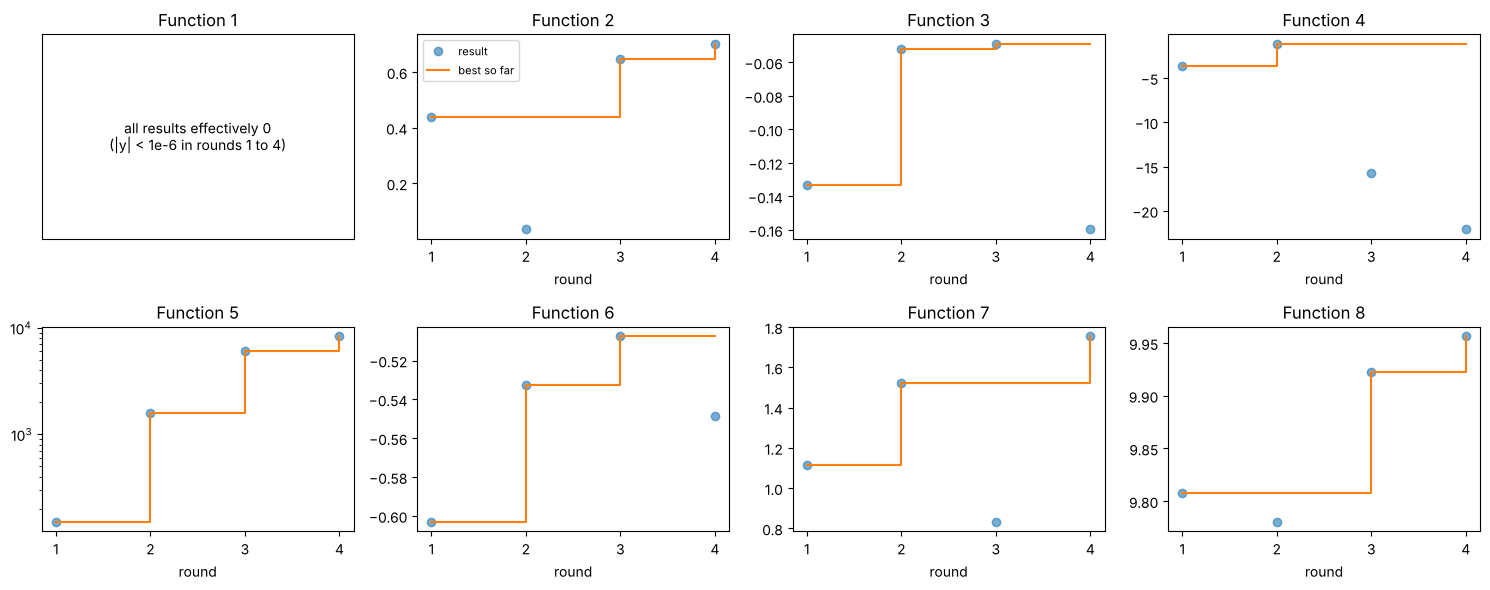

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, f in zip(axes.ravel(), sorted(by_fn)):
    rs = [t[0] for t in by_fn[f]]
    ys = np.array([t[1] for t in by_fn[f]])
    ax.plot(rs, ys, "o", alpha=0.6, label="result")
    ax.step(rs, np.maximum.accumulate(ys), where="post", label="best so far")
    ax.set_title(f"Function {f}")
    ax.set_xlabel("round")
    ax.set_xticks(rs)
    if f == 5:
        ax.set_yscale("log")
    if f == 1:   # every result is ~0 (|y| < 1e-18), so a numeric axis is meaningless
        ax.cla()
        ax.set_title("Function 1")
        ax.text(0.5, 0.5, "all results effectively 0\n(|y| < 1e-6 in rounds 1 to 4)", ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
axes.ravel()[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Model settings and diagnostics logged each round
Each round the pipeline logged, per function, its settings and two leave-one-out (LOO) checks on the fitted model: **LOO MAE** (average error predicting each point from the others, in transformed units) and a **calibration ratio** (near 1 means the model's stated uncertainty matches its real errors; above 1 means overconfident, below 1 underconfident).

In [5]:
print(f"{'fn':>3} {'acq':>4} {'param':>10} {'transform':>10} {'nu':>4} {'noise':>6} | LOO MAE by round (2,3,4,5)  | calibration (2,3,4,5)")
logs = {r: json.loads((DATA / "rounds" / f"round_0{r}_queries.json").read_text()) for r in (2, 3, 4, 5)}
for f in sorted(by_fn):
    k = f"function_{f}"
    c = logs[5]["functions"][k]["config"]
    param = f"kappa={c['kappa']}" if c["acquisition"] == "ucb" else f"xi={c['xi']}"
    mae = [logs[r]["functions"][k]["diagnostics"]["loo_mae"] for r in (2, 3, 4, 5)]
    cal = [logs[r]["functions"][k]["diagnostics"]["loo_calibration_ratio"] for r in (2, 3, 4, 5)]
    print(f"{f:>3} {c['acquisition']:>4} {param:>10} {c['transform']:>10} {c['nu']:>4} {str(c['noise']):>6} | "
          + " ".join(f"{m:6.3f}" for m in mae) + "  | " + " ".join(f"{x:5.2f}" for x in cal))
same = all(logs[2]["functions"][k]["config"] == logs[3]["functions"][k]["config"] == logs[4]["functions"][k]["config"] == logs[5]["functions"][k]["config"]
           for k in logs[4]["functions"])
print("\nSettings identical across rounds 2 to 5:", same)

 fn  acq      param  transform   nu  noise | LOO MAE by round (2,3,4,5)  | calibration (2,3,4,5)
  1  ucb  kappa=3.0       rank  2.5   True |  0.353  0.362  0.369  0.365  |  1.25  1.22  1.31  1.28
  2  ucb  kappa=2.0       none  1.5   True |  0.128  0.136  0.117  0.123  |  1.23  1.07  1.02  1.01
  3   ei    xi=0.01       none  2.5   True |  0.058  0.050  0.053  0.055  |  1.08  1.04  1.28  1.30
  4  ucb  kappa=2.0  signedlog  2.5   True |  0.143  0.297  0.293  0.280  |  0.74  1.07  0.98  0.89
  5  ucb  kappa=1.5      log1p  2.5  False |  1.536  1.057  1.000  0.997  |  1.53  1.08  1.07  1.18
  6   ei    xi=0.01       none  2.5   True |  0.279  0.258  0.251  0.230  |  1.19  1.19  1.18  1.13
  7  ucb  kappa=2.5       none  2.5   True |  0.202  0.184  0.184  0.152  |  0.99  0.89  0.85  0.69
  8  ucb  kappa=1.5       none  2.5   True |  0.101  0.096  0.087  0.082  |  0.78  0.75  0.72  0.71

Settings identical across rounds 2 to 5: True


Reading the table:
* The settings did not change between rounds 2 and 5: differences in queries come from new data, not from retuning.
* Functions 1 and 5 have the largest calibration ratios (above 1.2 and 1.5 early on), meaning the model was overconfident there.
* Function 5's LOO error fell from 1.54 to 1.00 as more points arrived, while function 1's stayed high (about 0.36): its outputs are almost all near zero, which is why a rank transform was used.
* The lengthscales printed in each log (`data/rounds/*.json`) show which inputs the model found relevant; values at the upper bound (10) suggest an input has little effect, or that there is not enough data to tell.

## 5. Limits to keep in mind
* Few points per function, so the model is uncertain away from sampled regions.
* Queries were chosen adaptively, so the data is not a random sample of each function.
* One evaluation per point: a high value could be noise.
* Round 5 results are not included yet.

See `MODEL_CARD.md` and `DATASHEET.md` for the full discussion.